PROJECT INTRODUCTION

BIG BAZAAR CUSTOMER SEGMENTATION USING K-MEANS CLUSTERING

Objective:
To segment Big Bazaar customers into distinct groups based on
their annual income, spending score, visit frequency and purchasing
behaviour using a Python-based K-Means clustering model.

1. Import Required Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

2. Load Dataset


In [ ]:
df = pd.read_csv("Big_Bazaar_Customer_Segmentation_Dataset.csv")

In [ ]:
df.head()

,Customer_ID,Age,Annual_Income,Spending_Score,Visit_Frequency,Total_Purchases,Average_Transaction_Value
0,1,37,55455.72,69.79,21.43,33.80,892.46
1,2,44,75073.20,37.67,3.41,9.66,1226.25
2,3,39,73394.66,85.66,20.10,43.47,3682.73
3,4,30,72304.09,94.43,30.49,60.32,2040.32
4,5,34,45135.29,27.92,6.89,15.10,733.15


3. Understand the dataset

In [ ]:
df.shape

(303, 7)

In [ ]:
df.columns

Index(['Customer_ID', 'Age', 'Annual_Income', 'Spending_Score',
       'Visit_Frequency', 'Total_Purchases', 'Average_Transaction_Value'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Customer_ID                303 non-null    int64  
 1   Age                        303 non-null    int64  
 2   Annual_Income              300 non-null    float64
 3   Spending_Score             300 non-null    float64
 4   Visit_Frequency            300 non-null    float64
 5   Total_Purchases            303 non-null    float64
 6   Average_Transaction_Value  303 non-null    float64
dtypes: float64(5), int64(2)
memory usage: 16.7 KB


In [ ]:
df.describe()

,Customer_ID,Age,Annual_Income,Spending_Score,Visit_Frequency,Total_Purchases,Average_Transaction_Value
count,303.000000,303.000000,300.000000,300.000000,300.000000,303.000000,303.000000
mean,149.547855,35.900990,63875.429267,55.998700,11.911967,24.813069,1537.774818
std,86.917618,9.804552,27148.087706,26.182683,7.449628,17.096291,786.209072
min,1.000000,18.000000,15000.000000,10.760000,1.400000,1.240000,422.830000
25%,74.500000,29.000000,40403.517500,32.125000,5.715000,10.585000,957.525000
50%,149.000000,36.000000,62151.215000,48.680000,8.595000,17.810000,1234.130000
75%,224.500000,43.000000,86013.422500,81.347500,18.120000,36.780000,1910.685000
max,300.000000,61.000000,136747.930000,100.000000,32.290000,81.930000,3885.470000


4. Data cleaning

In [ ]:
df.isnull().sum()

,0
Customer_ID,0
Age,0
Annual_Income,3
Spending_Score,3
Visit_Frequency,3
Total_Purchases,0
Average_Transaction_Value,0


In [ ]:
df.duplicated().sum()

np.int64(3)

In [ ]:
df = df.drop_duplicates()

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df['Annual_Income'] = df['Annual_Income'].fillna(
    df['Annual_Income'].median()
)

df['Spending_Score'] = df['Spending_Score'].fillna(
    df['Spending_Score'].median()
)

df['Visit_Frequency'] = df['Visit_Frequency'].fillna(
    df['Visit_Frequency'].median()
)

In [ ]:
df.isnull().sum()

,0
Customer_ID,0
Age,0
Annual_Income,0
Spending_Score,0
Visit_Frequency,0
Total_Purchases,0
Average_Transaction_Value,0


In [ ]:
print("Rows and columns:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Rows and columns: (300, 7)

Missing values:
Customer_ID                  0
Age                          0
Annual_Income                0
Spending_Score               0
Visit_Frequency              0
Total_Purchases              0
Average_Transaction_Value    0
dtype: int64

Duplicate rows: 0


5. Exploratory Data Analysis (EDA)

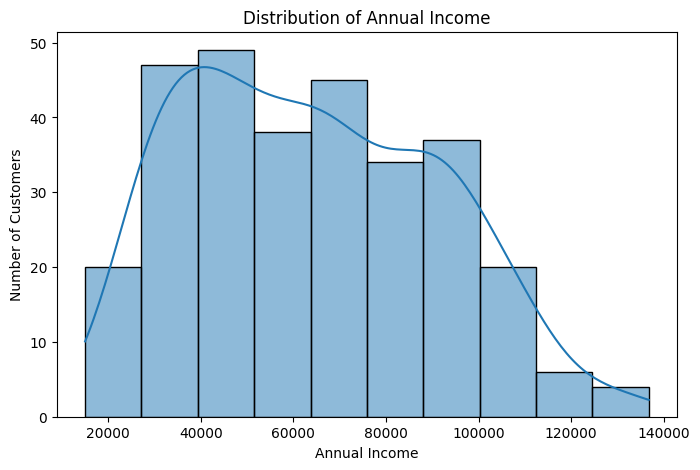

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df['Annual_Income'], kde=True)

plt.title('Distribution of Annual Income')
plt.xlabel('Annual Income')
plt.ylabel('Number of Customers')

plt.show()

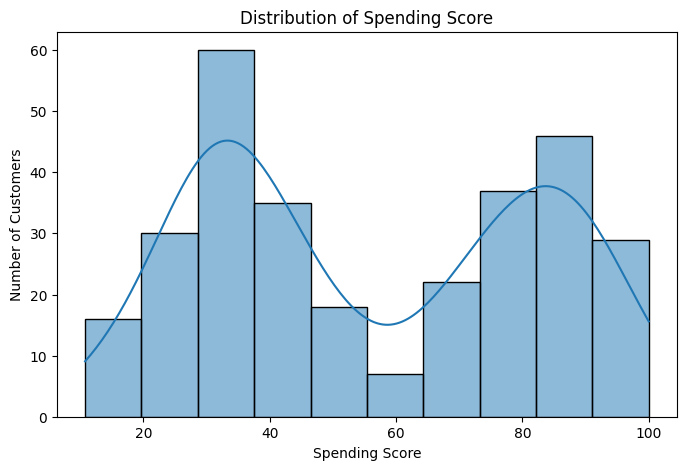

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df['Spending_Score'], kde=True)

plt.title('Distribution of Spending Score')
plt.xlabel('Spending Score')
plt.ylabel('Number of Customers')

plt.show()

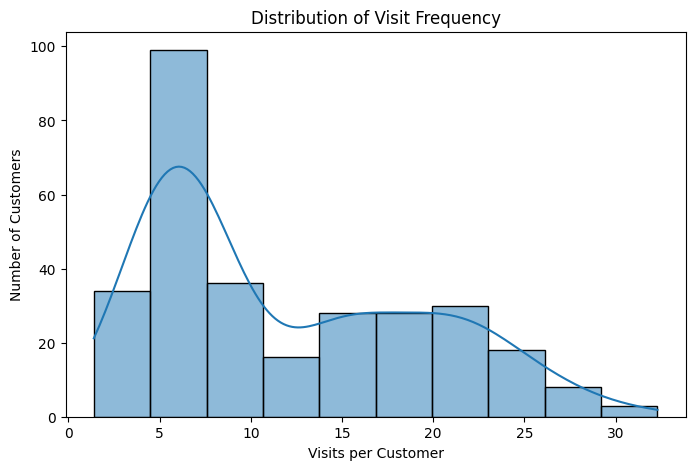

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df['Visit_Frequency'], kde=True)

plt.title('Distribution of Visit Frequency')
plt.xlabel('Visits per Customer')
plt.ylabel('Number of Customers')

plt.show()

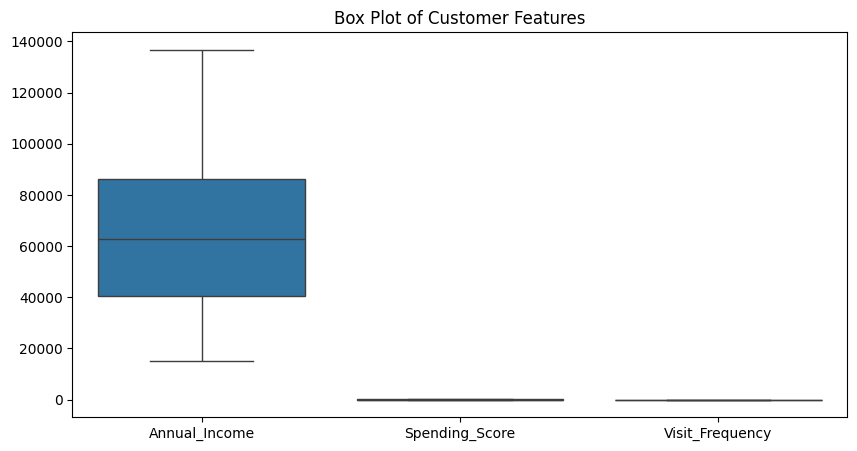

In [ ]:
plt.figure(figsize=(10,5))

sns.boxplot(
    data=df[['Annual_Income', 'Spending_Score', 'Visit_Frequency']]
)

plt.title('Box Plot of Customer Features')

plt.show()

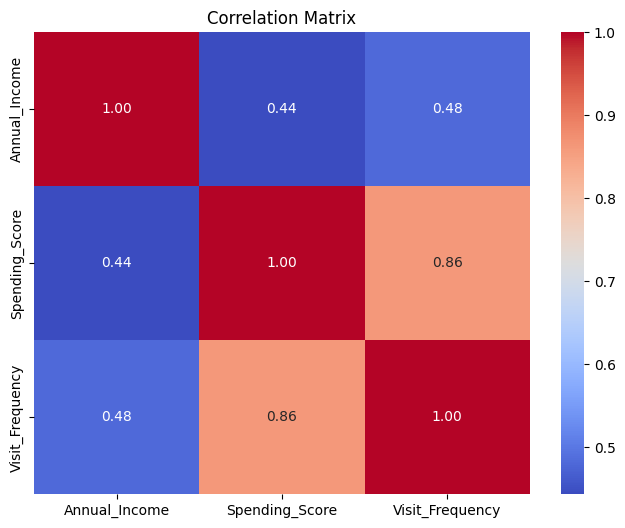

In [ ]:
plt.figure(figsize=(8,6))

correlation = df[
    ['Annual_Income',
     'Spending_Score',
     'Visit_Frequency']
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix')

plt.show()

6. Feature Selection

In [ ]:
features = [
    'Annual_Income',
    'Spending_Score',
    'Visit_Frequency',
    'Total_Purchases',
    'Average_Transaction_Value'
]

X = df[features]

X.head()

,Annual_Income,Spending_Score,Visit_Frequency,Total_Purchases,Average_Transaction_Value
0,55455.72,69.79,21.43,33.80,892.46
1,75073.20,37.67,3.41,9.66,1226.25
2,73394.66,85.66,20.10,43.47,3682.73
3,72304.09,94.43,30.49,60.32,2040.32
4,45135.29,27.92,6.89,15.10,733.15


In [ ]:
X.describe()

,Annual_Income,Spending_Score,Visit_Frequency,Total_Purchases,Average_Transaction_Value
count,300.000000,300.000000,300.000000,300.000000,300.000000
mean,64031.730000,56.188167,11.945100,24.953500,1542.732833
std,26968.913865,26.041753,7.426965,17.122859,788.472461
min,15000.000000,10.760000,1.400000,1.240000,422.830000
25%,40628.940000,32.302500,5.775000,10.600000,957.682500
50%,62716.990000,48.920000,8.760000,18.070000,1236.070000
75%,86013.422500,81.347500,18.120000,36.965000,1928.135000
max,136747.930000,100.000000,32.290000,81.930000,3885.470000


7. Feature Scaling

In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [ ]:
X_scaled[:5]

array([[-0.31852744,  0.52318137,  1.27922341,  0.51751178, -0.82610284],
       [ 0.41009878, -0.71228337, -1.15112439, -0.89465511, -0.40205796],
       [ 0.34775498,  1.13360557,  1.09984701,  1.08319753,  2.71864   ],
       [ 0.30724937,  1.47093514,  2.50114077,  2.06890641,  0.63213185],
       [-0.70184558, -1.08730769, -0.68177864, -0.57642032, -1.02848934]])

In [ ]:
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=features
)

X_scaled_df.describe()

,Annual_Income,Spending_Score,Visit_Frequency,Total_Purchases,Average_Transaction_Value
count,3.000000e+02,3.000000e+02,3.000000e+02,3.000000e+02,3.000000e+02
mean,-1.302662e-16,-3.552714e-17,2.309264e-16,1.065814e-16,1.125026e-16
std,1.001671e+00,1.001671e+00,1.001671e+00,1.001671e+00,1.001671e+00
min,-1.821121e+00,-1.747350e+00,-1.422212e+00,-1.387217e+00,-1.422718e+00
25%,-8.692190e-01,-9.187391e-01,-8.321581e-01,-8.396660e-01,-7.432446e-01
50%,-4.883166e-02,-2.795630e-01,-4.295727e-01,-4.026782e-01,-3.895827e-01
75%,8.164371e-01,9.677294e-01,8.328055e-01,7.026613e-01,4.896127e-01
max,2.700802e+00,1.685180e+00,2.743906e+00,3.333071e+00,2.976200e+00


8. Finding the Optimal Number of Clusters

In [ ]:
inertia = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

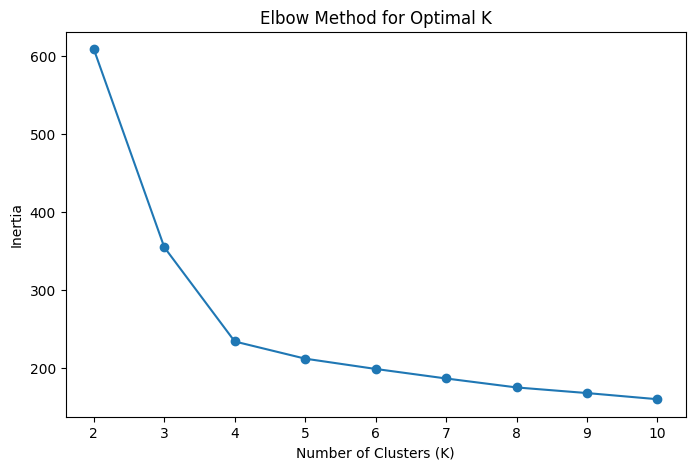

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    inertia,
    marker='o'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal K')

plt.show()

In [ ]:
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

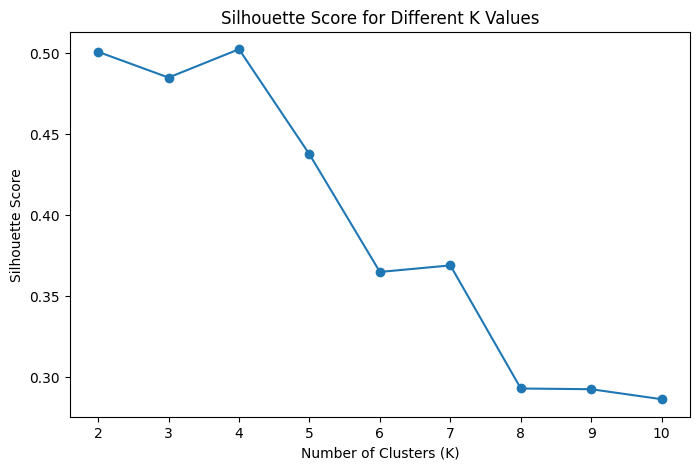

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score for Different K Values')

plt.show()

In [ ]:
best_k = range(2, 11)[np.argmax(silhouette_scores)]

print("Best K according to Silhouette Score:", best_k)
print("Best Silhouette Score:", max(silhouette_scores))

Best K according to Silhouette Score: 4
Best Silhouette Score: 0.5022243443082995


In [ ]:
best_k
max(silhouette_scores)

np.float64(0.5022243443082995)

In [ ]:
print("Best K:", best_k)
print("Best Silhouette Score:", max(silhouette_scores))

Best K: 4
Best Silhouette Score: 0.5022243443082995


9. Apply K-Means Clustering

In [ ]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

In [ ]:
df.head()

,Customer_ID,Age,Annual_Income,Spending_Score,Visit_Frequency,Total_Purchases,Average_Transaction_Value,Cluster
0,1,37,55455.72,69.79,21.43,33.80,892.46,2
1,2,44,75073.20,37.67,3.41,9.66,1226.25,0
2,3,39,73394.66,85.66,20.10,43.47,3682.73,1
3,4,30,72304.09,94.43,30.49,60.32,2040.32,1
4,5,34,45135.29,27.92,6.89,15.10,733.15,3


10. Cluster Analysis

In [ ]:
df['Cluster'].value_counts().sort_index()

,count
Cluster,
0,62
1,71
2,71
3,96


In [ ]:
cluster_summary = df.groupby('Cluster')[features].mean()

cluster_summary.round(2)

,Annual_Income,Spending_Score,Visit_Frequency,Total_Purchases,Average_Transaction_Value
Cluster,,,,,
0,82769.52,31.77,5.40,10.47,1105.38
1,94228.12,88.75,22.27,49.97,2776.68
2,56537.04,74.15,15.08,30.20,1502.22
3,35140.44,34.59,6.22,11.92,942.54


In [ ]:
cluster_summary = df.groupby('Cluster')[features].mean().round(2)

cluster_summary

,Annual_Income,Spending_Score,Visit_Frequency,Total_Purchases,Average_Transaction_Value
Cluster,,,,,
0,82769.52,31.77,5.40,10.47,1105.38
1,94228.12,88.75,22.27,49.97,2776.68
2,56537.04,74.15,15.08,30.20,1502.22
3,35140.44,34.59,6.22,11.92,942.54


In [ ]:
df.groupby('Cluster').size()

,0
Cluster,
0,62
1,71
2,71
3,96


In [ ]:
cluster_summary = df.groupby('Cluster')[features].mean().round(2)

cluster_summary

,Annual_Income,Spending_Score,Visit_Frequency,Total_Purchases,Average_Transaction_Value
Cluster,,,,,
0,82769.52,31.77,5.40,10.47,1105.38
1,94228.12,88.75,22.27,49.97,2776.68
2,56537.04,74.15,15.08,30.20,1502.22
3,35140.44,34.59,6.22,11.92,942.54


11. Customer Segment Identification

In [ ]:
cluster_names = {
    0: 'High-Income Low-Engagement',
    1: 'Premium Loyal',
    2: 'High-Potential',
    3: 'Budget Low-Value'
}

df['Segment'] = df['Cluster'].map(cluster_names)

In [ ]:
df[['Customer_ID', 'Cluster', 'Segment']].head(10)

,Customer_ID,Cluster,Segment
0,1,2,High-Potential
1,2,0,High-Income Low-Engagement
2,3,1,Premium Loyal
3,4,1,Premium Loyal
4,5,3,Budget Low-Value
5,6,3,Budget Low-Value
6,7,3,Budget Low-Value
7,8,0,High-Income Low-Engagement
8,9,1,Premium Loyal
9,10,1,Premium Loyal


12. Final Customer Segmentation

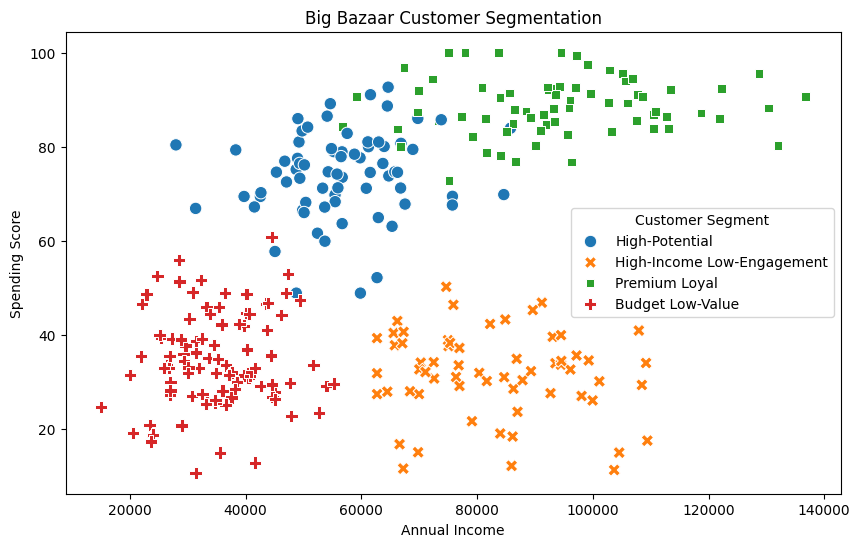

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Annual_Income',
    y='Spending_Score',
    hue='Segment',
    style='Segment',
    s=80
)

plt.title('Big Bazaar Customer Segmentation')
plt.xlabel('Annual Income')
plt.ylabel('Spending Score')
plt.legend(title='Customer Segment')

plt.show()

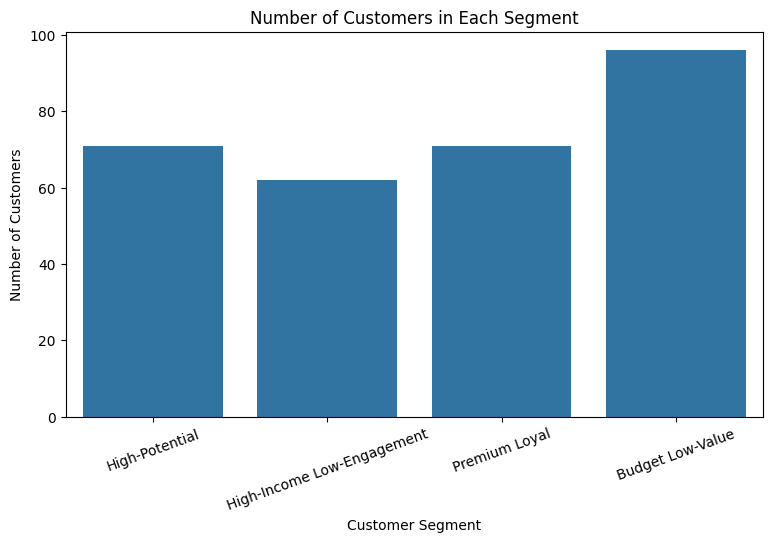

In [ ]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='Segment'
)

plt.title('Number of Customers in Each Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')

plt.xticks(rotation=20)

plt.show()

In [ ]:
final_silhouette = silhouette_score(
    X_scaled,
    df['Cluster']
)

print("Final Silhouette Score:", final_silhouette)
print("Final Inertia:", kmeans.inertia_)

Final Silhouette Score: 0.5022243443082995
Final Inertia: 234.01974487927444


In [ ]:
cluster_profile = df.groupby('Segment')[features].mean().round(2)

cluster_profile

,Annual_Income,Spending_Score,Visit_Frequency,Total_Purchases,Average_Transaction_Value
Segment,,,,,
Budget Low-Value,35140.44,34.59,6.22,11.92,942.54
High-Income Low-Engagement,82769.52,31.77,5.40,10.47,1105.38
High-Potential,56537.04,74.15,15.08,30.20,1502.22
Premium Loyal,94228.12,88.75,22.27,49.97,2776.68


In [ ]:
cluster_profile['Customer_Count'] = df.groupby('Segment').size()

cluster_profile

,Annual_Income,Spending_Score,Visit_Frequency,Total_Purchases,Average_Transaction_Value,Customer_Count
Segment,,,,,,
Budget Low-Value,35140.44,34.59,6.22,11.92,942.54,96
High-Income Low-Engagement,82769.52,31.77,5.40,10.47,1105.38,62
High-Potential,56537.04,74.15,15.08,30.20,1502.22,71
Premium Loyal,94228.12,88.75,22.27,49.97,2776.68,71


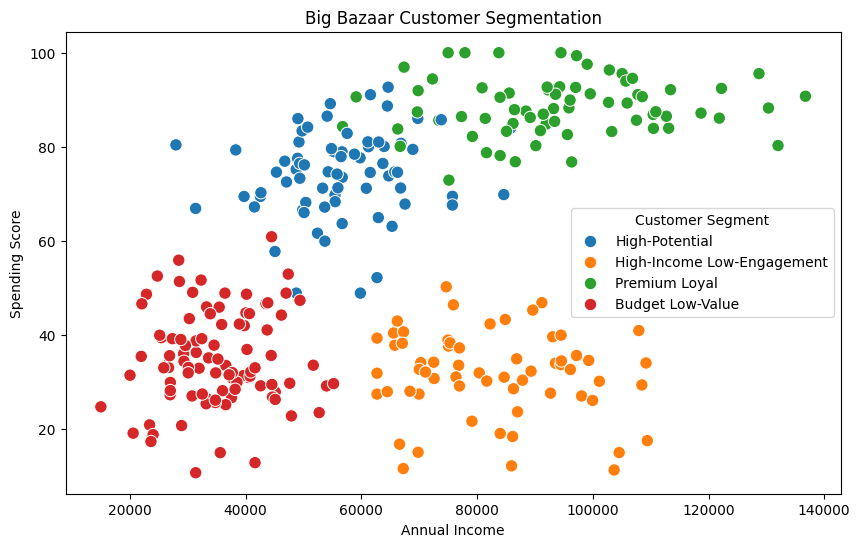

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Annual_Income',
    y='Spending_Score',
    hue='Segment',
    s=80
)

plt.title('Big Bazaar Customer Segmentation')
plt.xlabel('Annual Income')
plt.ylabel('Spending Score')
plt.legend(title='Customer Segment')

plt.show()

13. Customer Distribution

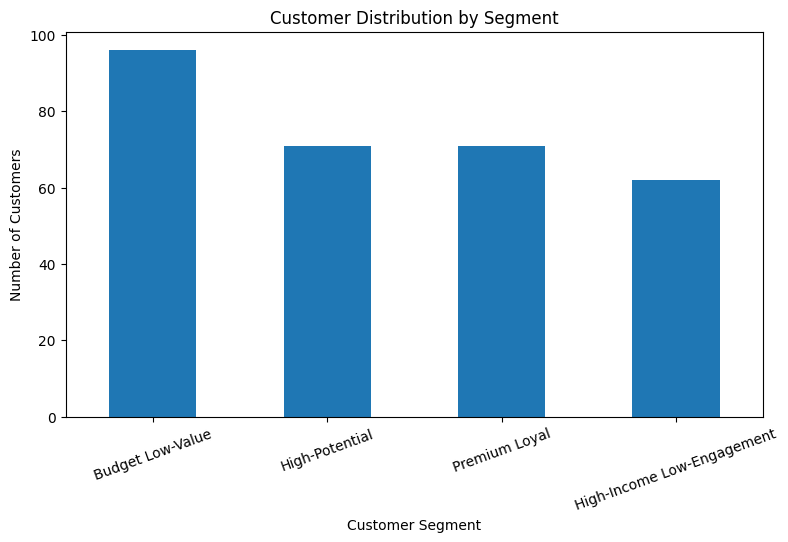

In [ ]:
segment_counts = df['Segment'].value_counts()

plt.figure(figsize=(9, 5))

segment_counts.plot(kind='bar')

plt.title('Customer Distribution by Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')

plt.xticks(rotation=20)
plt.show()

14. Model Evaluation

In [ ]:
final_silhouette = silhouette_score(
    X_scaled,
    df['Cluster']
)

print("Number of Clusters:", 4)
print("Silhouette Score:", round(final_silhouette, 4))
print("Inertia:", round(kmeans.inertia_, 2))

Number of Clusters: 4
Silhouette Score: 0.5022
Inertia: 234.02


15. Export Final Dataset

In [ ]:
output_file = 'Big_Bazaar_Customer_Segmentation_Final.csv'

df.to_csv(output_file, index=False)

print("Final dataset saved as:", output_file)

Final dataset saved as: Big_Bazaar_Customer_Segmentation_Final.csv


In [ ]:
final_summary = df.groupby('Segment').agg(
    Customers=('Customer_ID', 'count'),
    Average_Income=('Annual_Income', 'mean'),
    Average_Spending=('Spending_Score', 'mean'),
    Average_Visits=('Visit_Frequency', 'mean'),
    Average_Purchases=('Total_Purchases', 'mean'),
    Average_Transaction=('Average_Transaction_Value', 'mean')
).round(2)

final_summary

,Customers,Average_Income,Average_Spending,Average_Visits,Average_Purchases,Average_Transaction
Segment,,,,,,
Budget Low-Value,96,35140.44,34.59,6.22,11.92,942.54
High-Income Low-Engagement,62,82769.52,31.77,5.40,10.47,1105.38
High-Potential,71,56537.04,74.15,15.08,30.20,1502.22
Premium Loyal,71,94228.12,88.75,22.27,49.97,2776.68


CONCLUSION:-
The project successfully implemented a Python-based K-Means clustering model to segment Big Bazaar customers according to their purchasing behaviour. The customer data was cleaned by handling missing values and duplicate records, followed by exploratory data analysis and feature standardization. The Elbow Method and Silhouette Score were used to determine the appropriate number of clusters. Four distinct customer segments were identified: Premium Loyal, High-Potential, High-Income Low-Engagement and Budget Low-Value customers. The segmentation provides useful insights that can help Big Bazaar develop targeted promotional strategies, improve customer engagement and optimize sales.